# AP 155 Lab Exercise
---
## Exercise 10: Fourier transform

_Instructions_:
- **Report**: See instructions in Problems 1,2,3
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_: Pasion, Kyla Zarina
- _Student No._: 2024-09224
- _Section_: THR-WX-1

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 | 
| Code appropriateness  | XX | 20 | 
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_ 

---
## Section 1: Report

### Report figure

![Problem 1](./Figures/e10_figure0.png)
**Figure 1.** Fourier transform of a square wave

![Problem 2](./Figures/e10_figure4.png)
**Figure 2.** Original vs. Recovered Signal

![Problem 3](./Figures/e10_figure5_fs100.png)
**Figure 3.** Above Nyquist Rate (No Aliasing)

![Problem 3](./Figures/e10_figure5_fs12.png)
**Figure 4.** Below Nyquist Rate (Aliasing)

EDIT ME. See instruction above for what to include. Insert caption here, a short description what the figure illustrates. The syntax in markdown for putting a figure is `![Description](local_file_name.png)` or `<img src="/path/to_image.jpg" alt="Alt text" width=45%>`. Make sure the figure has complete elements.

### Report discussion

EDIT ME. See instruction above for what to include. Insert your discussions here. Discuss your key results with at most 150 words per question.

### Other comments
- EDIT ME
- A self reflection can be placed here.
- This portion is not graded.
- You may insert further questions here.


---
## Section 2: Code

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math
from scipy import signal

### Problem 1: Exploring FT of varying waveforms

Given the waveforms from the pool below, produce a $1\times3$ plot containing the following: 
1) the signal, with its variations, 
2) the magnitude of its Fourier transform, and 
3) the phase information of the transform (up to you if unwrapped or not). 
    
Discussion: 2-3 sentences explaining how changing the shape of the input signal affects it transform. 
Ex: for the Gaussian waveform, how does it Fourier transform change based on increasing or decreasing sigma?

Waveforms you can try (prefarably non-sinusoidal):
- Square wave (both single and periodic)
- Triangle wave (sawtooth, ramp, reverse ramp)
- Gaussian function (vary sigma)
- Finite-time sinusoid
- Gaussian wave packet
- Dirac-delta 

In [2]:
# Parameters
N = 1000
frequency = 2
amplitude = 1
mu = 5.0 # Center (mean) of the pulse
sigma = 1.0 # Width (std)

# Define time axis
time_axis = np.linspace(0, 10, N)
deltaT = time_axis[1] - time_axis[0]

# Different Waveforms
square_wave = amplitude * signal.square(2 * np.pi * frequency * time_axis)
triangle_wave = amplitude * signal.sawtooth(2 * np.pi * frequency * time_axis, width = 0.5)
gaussian_wave = 1 / (sigma * np.sqrt(2*np.pi)) * np.exp(-((time_axis - mu) ** 2) / (2 * (sigma**2)))

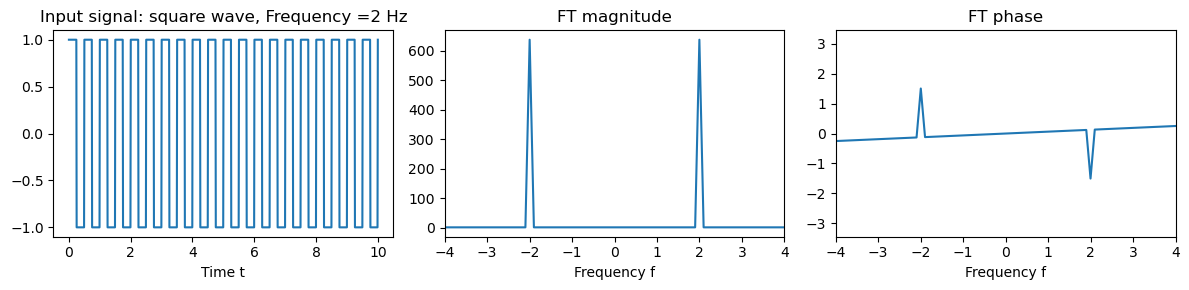

In [3]:
# Square wave
freqs = np.fft.fftfreq(N, deltaT)
sw_ft = np.fft.fft(square_wave)

freqs = np.fft.fftshift(freqs) # # Q: Why do fftshift?
sw_ft = np.fft.fftshift(sw_ft) # Yk = np.fft.fftshift(Yk)

sw_mag = np.abs(sw_ft)
sw_phase = np.angle(sw_ft)
sw_phase = np.unwrap(sw_phase) # Q: Why unwrap?

fig, ax = plt.subplots(1,3, figsize=(12,3))

ax[0].set_title("Input signal: square wave, Frequency =2 Hz")
ax[0].set_xlabel("Time t")
ax[0].plot(time_axis, square_wave)

ax[1].set_title("FT magnitude")
ax[1].set_xlabel("Frequency f")
ax[1].plot(freqs, sw_mag)
ax[1].set_xlim(-4, 4)

ax[2].set_title("FT phase")
ax[2].set_xlabel("Frequency f")
ax[2].plot(freqs, sw_phase)
ax[2].set_xlim(-4, 4)

fig.tight_layout()
plt.savefig("Figures/e10_figure0", dpi=300)
plt.show()

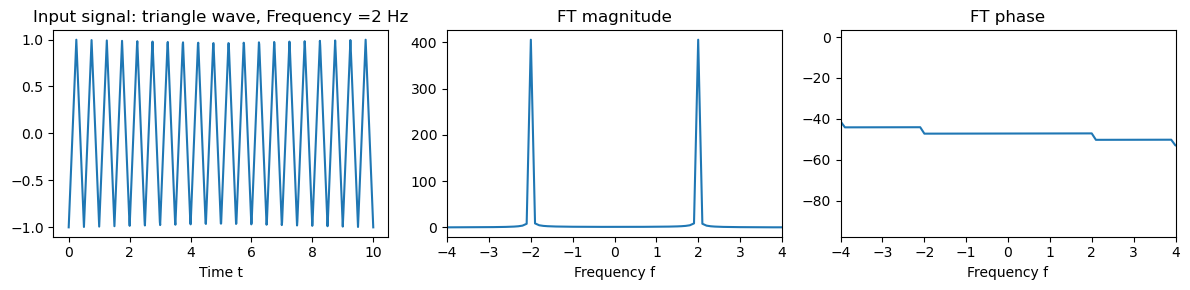

In [4]:
# Triangle wave
freqs = np.fft.fftfreq(N, deltaT)
tw_ft = np.fft.fft(triangle_wave)

freqs = np.fft.fftshift(freqs) # # Q: Why do fftshift?
tw_ft = np.fft.fftshift(tw_ft) # Yk = np.fft.fftshift(Yk)

tw_mag = np.abs(tw_ft)
tw_phase = np.angle(tw_ft)
tw_phase = np.unwrap(tw_phase) # Q: Why unwrap?

fig, ax = plt.subplots(1,3, figsize=(12,3))

ax[0].set_title("Input signal: triangle wave, Frequency =2 Hz")
ax[0].set_xlabel("Time t")
ax[0].plot(time_axis, triangle_wave)

ax[1].set_title("FT magnitude")
ax[1].set_xlabel("Frequency f")
ax[1].plot(freqs, tw_mag)
ax[1].set_xlim(-4, 4)

ax[2].set_title("FT phase")
ax[2].set_xlabel("Frequency f")
ax[2].plot(freqs, tw_phase)
ax[2].set_xlim(-4, 4)

fig.tight_layout()
plt.savefig("Figures/e10_figure1", dpi=300)
plt.show()

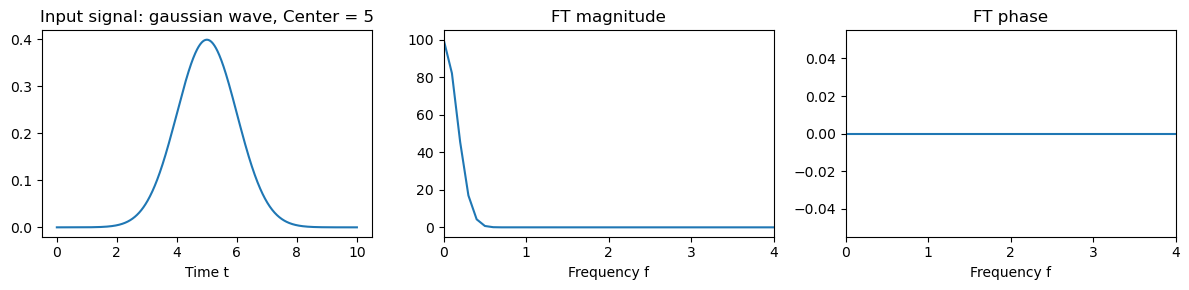

In [5]:
# Gaussian function
# Applying FFT

freqs = np.fft.fftfreq(N, deltaT)
gw_ft = np.fft.fft(gaussian_wave)

freqs = np.fft.fftshift(freqs) # # Q: Why do fftshift?
gw_ft = np.fft.fftshift(gw_ft) # Yk = np.fft.fftshift(Yk)

gw_mag = np.abs(gw_ft)
gw_phase = np.angle(gw_mag)
gw_phase = np.unwrap(gw_phase) # Q: Why unwrap?

pos = freqs >=0 # Select nonnegative frequencies

fig, ax = plt.subplots(1,3, figsize=(12,3))

ax[0].set_title("Input signal: gaussian wave, Center = 5")
ax[0].set_xlabel("Time t")
ax[0].plot(time_axis, gaussian_wave)

ax[1].set_title("FT magnitude")
ax[1].set_xlabel("Frequency f")
ax[1].plot(freqs[pos], gw_mag[pos])
ax[1].set_xlim(0, 4)

ax[2].set_title("FT phase")
ax[2].set_xlabel("Frequency f")
ax[2].plot(freqs[pos], gw_phase[pos])
ax[2].set_xlim(0, 4)

fig.tight_layout()
plt.savefig("Figures/e10_figure2", dpi=300)
plt.show()

### Problem 2: Signal Processing in 1D (Fill in the blanks/Code to get to the desired result)

Steps performed: 

1) Create a composite signal from multiple sinusoids with three frequencies, get fft of clean signal
2) Add noise (gaussian noise)
3) Add a window (Hann)
4) Get fft of the noisy signal
5) filter frequencies below a threshold
6) get the inverse fft
7) compare the result

Discussion: Try running the procedure with a lower number of N (N<25000). What does lowering N do to the original signal? Will I still be able to recover that original signal if I add the noise below? Is there a limit of N to which I can recover the signal well? Why? (Answer in ~3 sentences)


In [6]:
#Make a wave (cosine or sine) - you can do combo of waves
N = 25000
dt = 0.0002 #if spacing is 0.0002, then frequency is 5000 Hz 
t_ = np.arange(N)*dt

freqs = [130, 230, 180]
phase = [np.pi/3, np.pi/4, np.pi/6]


signal_original = np.sum([np.cos(2*np.pi*f*t_ + p) for f, p in zip(freqs, phase)], axis=0)

<function matplotlib.pyplot.show(close=None, block=None)>

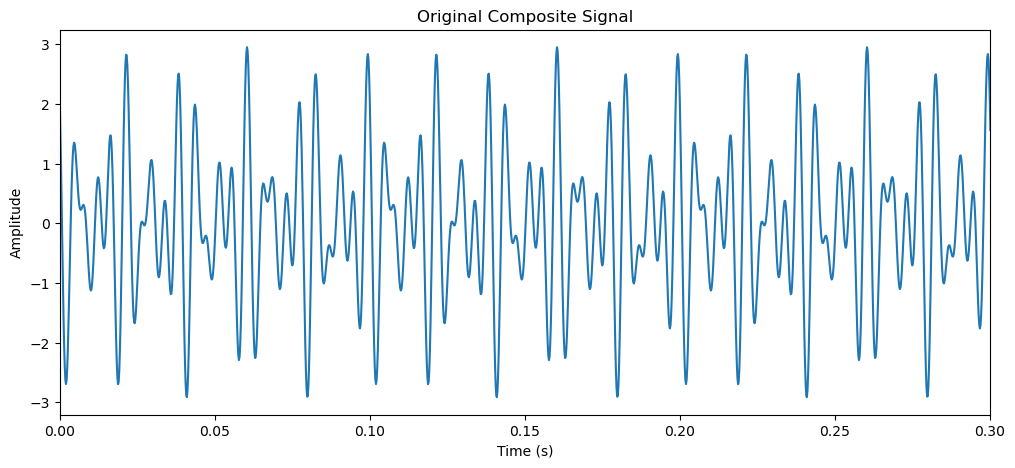

In [7]:
fig, ax = plt.subplots(figsize= (12,5))
ax.plot(t_, signal_original)
ax.set_xlim(0,0.3)
ax.set_xlabel("Time (s)")
ax.set_ylabel("Amplitude")
ax.set_title("Original Composite Signal")
plt.show

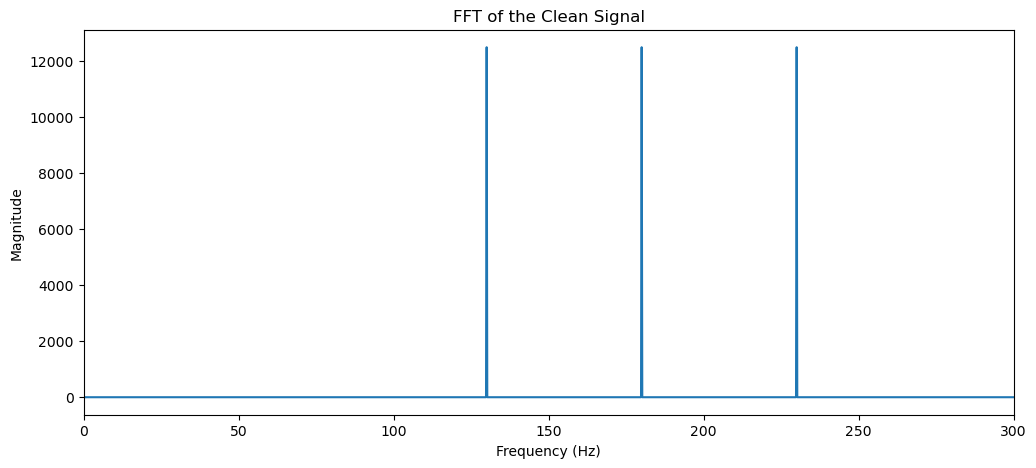

In [8]:
#FILL: Plot the fourier transform of the clean, original signal

freq_axis = np.fft.fftfreq(N, dt)
clean_ft = np.fft.fft(signal_original)

freq_axis = np.fft.fftshift(freq_axis)
clean_ft = np.fft.fftshift(clean_ft)
    
clean_mag = np.abs(clean_ft)

# Plot the positive-frequency magnitude spectrum
pos = freq_axis >= 0

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(freq_axis[pos], clean_mag[pos])
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("Magnitude")
ax.set_title("FFT of the Clean Signal")
ax.set_xlim(0, 300)
plt.show()

In [9]:
rng = np.random.default_rng()

#Define parameters of Gaussian noise)
mean = 0
std = 2

noise = rng.normal(loc = mean, scale = std, size = len(t_)) #Add noise to every data point
#Noisy data here
noisy_data = signal_original + noise*5

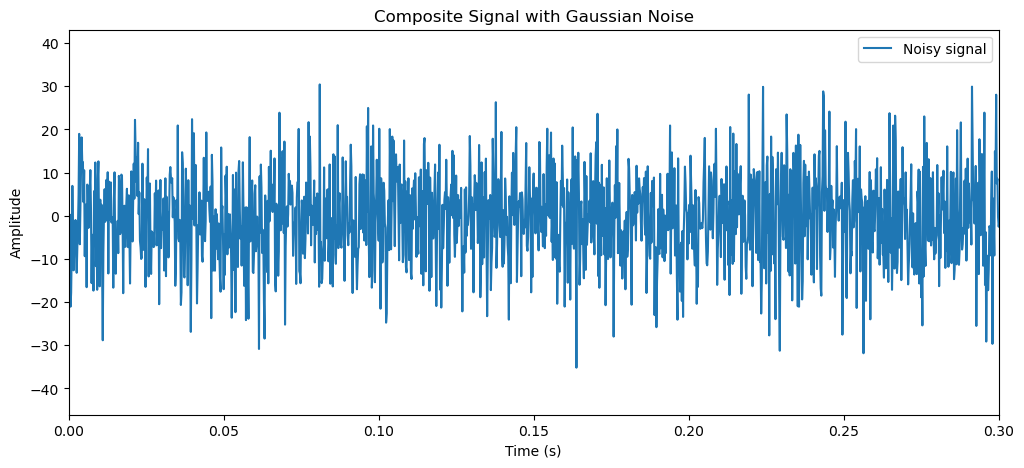

In [10]:
fig, ax = plt.subplots(figsize= (12,5))
ax.plot(t_, noisy_data, label="Noisy signal")
ax.set_xlim(0,0.3)
ax.set_xlabel("Time (s)")
ax.set_ylabel("Amplitude")
ax.set_title("Composite Signal with Gaussian Noise")
ax.legend()

plt.show()

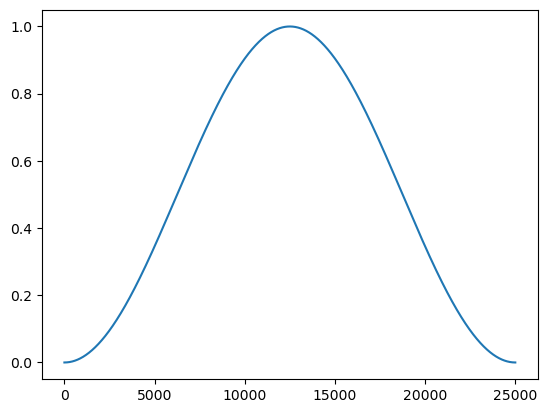

In [11]:
window = np.hanning(len(noisy_data)) #Create a window the size of the data length
plt.plot(window)

In [12]:
#fourier of hanning window
windowSigPeaks = np.abs(np.fft.fftshift(np.fft.fft(window)))
windowSigFreqs = np.fft.fftshift(np.fft.fftfreq(N, dt))


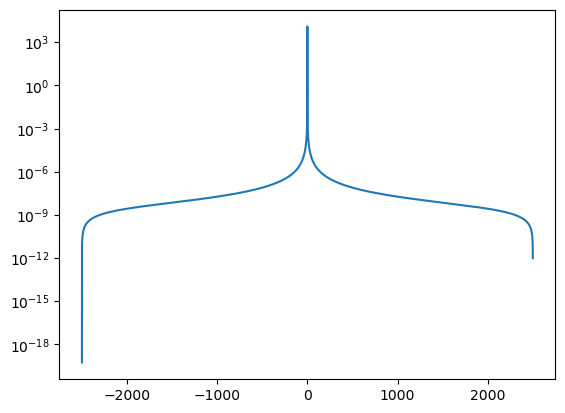

In [13]:
plt.plot(windowSigFreqs, windowSigPeaks)
plt.yscale('log')

In [14]:
noisyFourier = np.fft.fft(noisy_data*window)

noisySigPeaks = np.abs(np.fft.fftshift(np.fft.fft(noisy_data*window)))


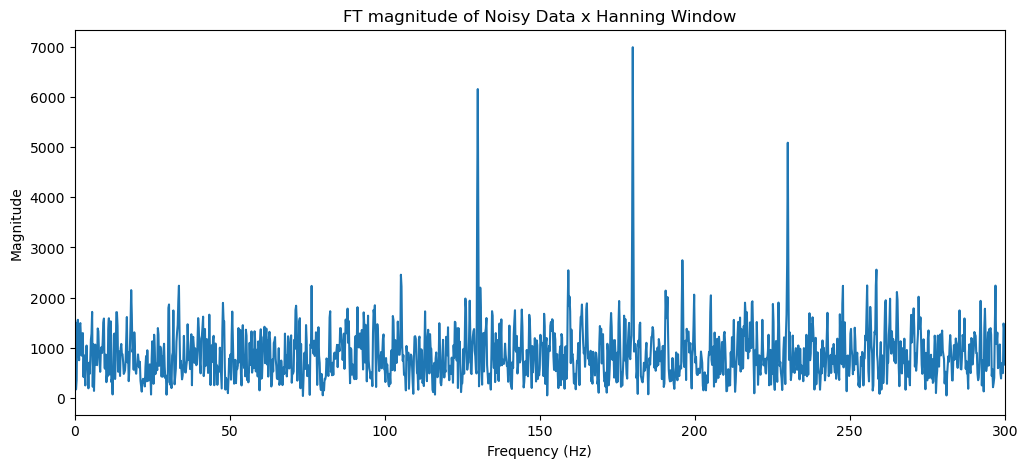

In [15]:
noisy_mag = np.abs(np.fft.fftshift(noisyFourier))

pos = freq_axis >= 0

plt.figure(figsize=(12, 5))
plt.plot(freq_axis[pos], noisy_mag[pos])
plt.xlim(0, 300)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude")
plt.title("FT magnitude of Noisy Data x Hanning Window")
plt.savefig("Figures/e10_figure3", dpi=300)
plt.show()

In [16]:
# Fill: Find a suitable threshold value to filter the noise in fourier space

threshold = 0.6 * np.abs(noisyFourier).max()

filteredFourier = noisyFourier.copy()
filteredFourier[np.abs(noisyFourier) < threshold] = 0

kept_freqs = np.fft.fftfreq(N, dt)[filteredFourier != 0 ]

print("Frequencies kept:", kept_freqs)
print("Positive frequencies kept:", kept_freqs[kept_freqs > 0])

Frequencies kept: [ 130.  180.  230. -230. -180. -130.]
Positive frequencies kept: [130. 180. 230.]


In [17]:
# Fill: with the cleaned signal in fourier space, convert it back to the time domain

recoveredSignal = np.real(np.fft.ifft(filteredFourier))
recoveredSignal = recoveredSignal / window.mean()

RMS error = 0.22089


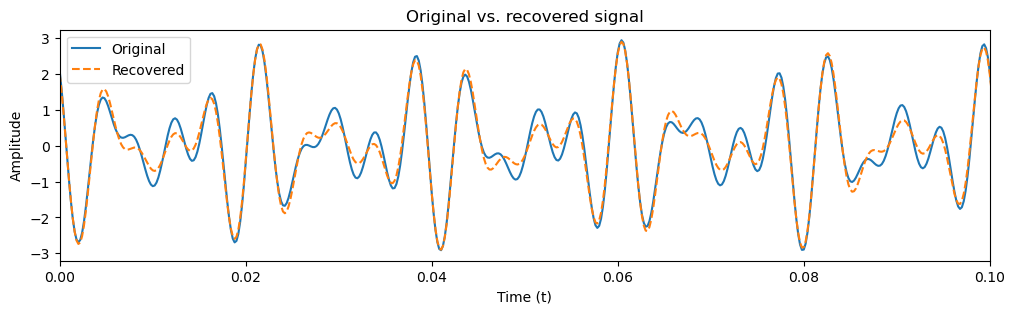

In [18]:
# Plot the recovered signal
# fig, ax = plt.subplots(figsize= (12,5))
# ax.plot(t_, recoveredSignal)
# ax.set_xlim(0,0.3)

error = np.sqrt(np.mean((recoveredSignal - signal_original)**2))
print(f"RMS error = {error:.5f}")

fig, ax = plt.subplots(figsize=(12, 3))
ax.set_title("Original vs. recovered signal")
ax.set_xlabel("Time (t)")
ax.set_ylabel("Amplitude")
ax.plot(t_, signal_original, label="Original")
ax.plot(t_, recoveredSignal, "--", label="Recovered")
ax.set_xlim(0, 0.1)
ax.legend()
plt.savefig("Figures/e10_figure4", dpi=300)
plt.show()

### Problem 3: Aliasing
1) Using different sampling frequencies (uniform sampling), generate a sinusoidal signal. Note the sampling frequencies, and the signal frequency. Use a sampling frequency above the Nyquist frequency, and another one below it.
3) Get their fourier transforms. Are they the same?
4) Plot: Show the fourier transform of an aliased signal, how it looks like in the time-domain, and how the actual signal looks like in the time domain if it's not aliased.
   
Discussion: Explain the report figure. Note the frequency of the signal you wanted to sample, the sampling frequencies used for the aliased and the non-aliased wave

Sampling rate = 100 Hz (Above Nyquist Rate (No Aliasing)): dominant frequency = 9.00 Hz


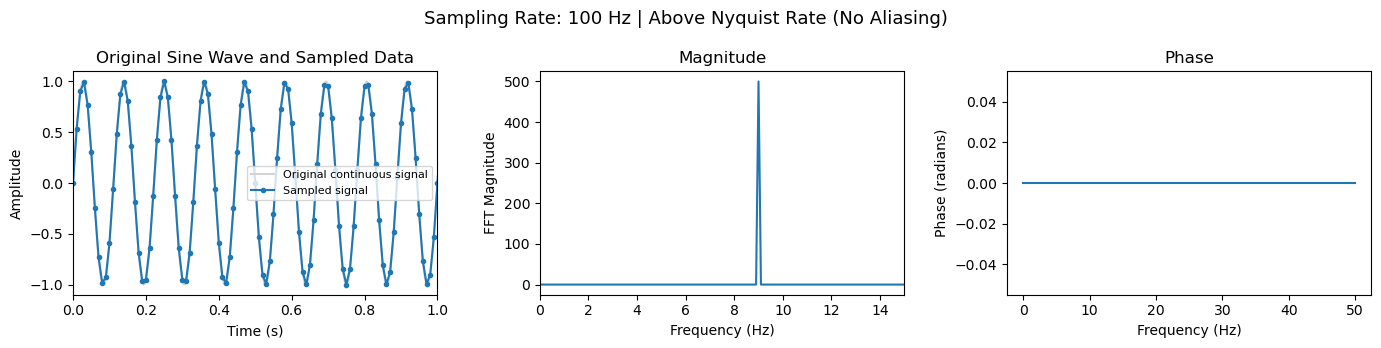

Sampling rate = 12 Hz (At or Below Nyquist Rate (Aliasing)): dominant frequency = 3.00 Hz


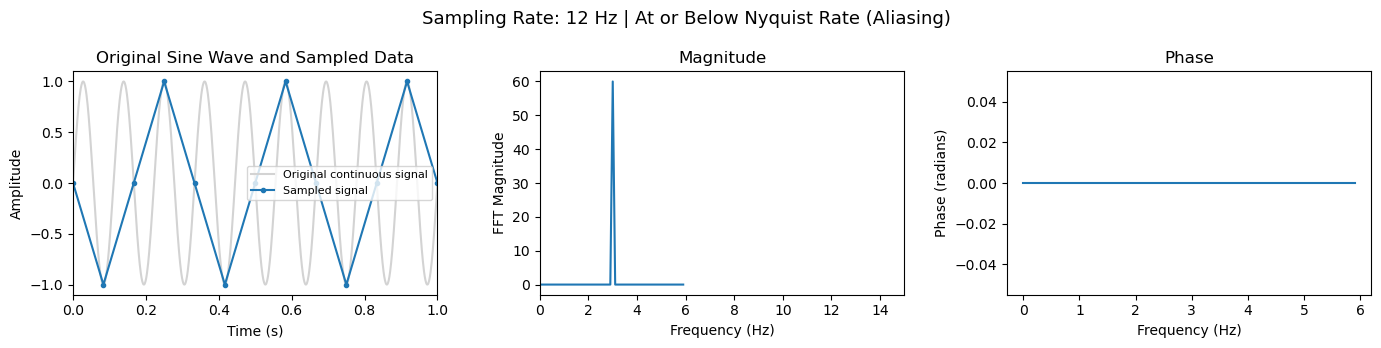

In [41]:
f = 9
T = 10
fs_list = [100, 12]  # Sampling rates: above and below the Nyquist rate

t_fine = np.linspace(0, T, 10000)
x_real = np.sin(2 * np.pi * f * t_fine)

for fs in fs_list:
    f_nyquist = 2 * f
    if fs > f_nyquist:
        nyq_label = "Above Nyquist Rate (No Aliasing)"
    else:
        nyq_label = "At or Below Nyquist Rate (Aliasing)"

    N = int(T * fs)
    t = np.linspace(0, T, N, endpoint=False)
    deltaT = t[1] - t[0]

    x = np.sin(2 * np.pi * f * t)

    freqs = np.fft.fftfreq(N, deltaT)
    x_ft = np.fft.fft(x)

    freqs = np.fft.fftshift(freqs)
    x_ft = np.fft.fftshift(x_ft)

    x_mag = np.abs(x_ft)
    x_phase = np.angle(x_mag)
    x_phase = np.unwrap(x_phase)

    pos = freqs >= 0

    print(
        f"Sampling rate = {fs} Hz ({nyq_label}): "
        f"dominant frequency = "
        f"{freqs[pos][np.argmax(x_mag[pos])]:.2f} Hz")

    fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))

    fig.suptitle(
        f"Sampling Rate: {fs} Hz | {nyq_label}",
        fontsize=13)

    ax[0].set_title("Original Sine Wave and Sampled Data")
    ax[0].set_xlabel("Time (s)")
    ax[0].set_ylabel("Amplitude")
    ax[0].plot(t_fine, x_real, color="lightgray",
               label="Original continuous signal")
    ax[0].plot(t, x, ".-", label="Sampled signal")
    ax[0].set_xlim(0, 1)
    ax[0].legend(fontsize=8)

    ax[1].set_title("Magnitude")
    ax[1].set_xlabel("Frequency (Hz)")
    ax[1].set_ylabel("FFT Magnitude")
    ax[1].plot(freqs[pos], x_mag[pos])
    ax[1].set_xlim(0, 15)

    ax[2].set_title("Phase")
    ax[2].set_xlabel("Frequency (Hz)")
    ax[2].set_ylabel("Phase (radians)")
    ax[2].plot(freqs[pos], x_phase[pos])

    fig.tight_layout()
    plt.savefig(f"Figures/e10_figure5_fs{fs}.png", dpi=300, bbox_inches="tight")
    plt.show()


#### Problem code summary

**Problem 1.** This code generates different waveforms and computes their Fourier transforms to examine how changes in the signal's shape affect its frequency components. It plots the original signal, the magnitude spectrum, and the phase spectrum to compare how waveform variations influence the distribution of frequencies and their corresponding phase information.

**Problem 2.** This code demonstrates 1D signal processing by combining three sinusoidal waves, adding Gaussian noise, and applying a Hann window before performing the Fast Fourier Transform (FFT). It filters out frequency components below a specified magnitude threshold, uses the inverse FFT to reconstruct the filtered signal, and compares the result with the original and noisy signals to evaluate the effectiveness of noise reduction.

**Problem 3.** This code compares how different sampling frequencies affect the reconstruction and frequency analysis of a sine wave. It uses the Nyquist criterion to determine whether aliasing may occur, then applies the Fast Fourier Transform (FFT) to examine the signal's frequency magnitude and phase. The plots show the original signal, sampled points, and frequency spectra to illustrate how the sampling rate affects the results.

---
## Section 3: Notes

In [20]:
import numpy as np
import matplotlib.pyplot as plt

### Fourier transform (from $t$-space to $\omega$-space)
$$ Y(\omega) = \int_{-\infty}^{+\infty} dt \frac{e^{-i\omega t}}{\sqrt{2\pi}}y(t)$$

### Inverse Fourier transform (from $\omega$-space to $t$-space)
$$ y(t) = \int_{-\infty}^{+\infty} d\omega Y(\omega) \frac{e^{i\omega t}}{\sqrt{2\pi}}$$

Something to think about: while we essentially do numerical integration, we do not impose h. Instead, we utilize the spacing of the dataset.

### Discrete FT/IFT

$$ Y_n = \frac{1}{\sqrt{2\pi}} \sum_{k=1}^N \left[(\cos(nk\theta)\Re\{y_k\}  +\sin(nk\theta)\Im\{y_k\} +i(\cos(nk\theta)\Im\{y_k\} −\sin(nk\theta)\Re\{y_k\})]\right]$$

$$ y_k = \frac{\sqrt{2\pi}}{N} \sum_{k=1}^N \left[(\cos(nk\theta)\Re\{Y_n\}  -\sin(nk\theta)\Im\{Y_n\} +i(\cos(nk\theta)\Im\{Y_n\} +\sin(nk\theta)\Re\{Y_n\})]\right]$$

Why bother it doing this way? 

It cleanly splits the real and imaginary part for both inputs and outputs, so that you can use a pair of floats rather than an aggregate complex data type (complex128 is just a pair of float64 anyway).

Using $Z=e^{−i\theta}, \rightarrow Z^{\pm nk} = e^{\mp ink\theta} = \cos(nk\theta)\mp i\sin(nk\theta)$.

(0.0, 4.0)

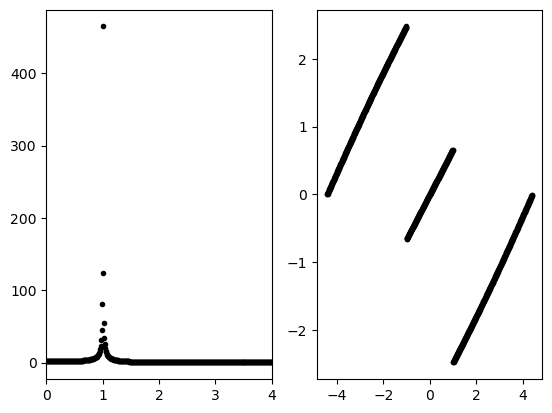

In [21]:
import numpy as np
import matplotlib.pyplot as plt

N = 1000
x = np.linspace(0, 18*2*np.pi, N)
deltaT = x[1] - x[0]

f = 1
y = np.cos(2*np.pi*f*x)

freqs = np.fft.fftfreq(N, deltaT)
Yk = np.fft.fft(y)

# # Q: Why do fftshift?
# Yk = np.fft.fftshift(Yk)

Yk_mag = np.abs(Yk)
Yk_phase = np.angle(Yk)
# Q: Why unwrap?
Yk_phase = np.unwrap(Yk_phase)

fig, ax = plt.subplots(1,2)

ax[0].plot(freqs, Yk_mag, "k.")
ax[1].plot(freqs, Yk_phase, "k.")
ax[0].set_xlim(0, 4)

### Waveforms of interest
- Sinusoid (single frequency, varying phase shift)
- Sum of sinusoids with different frequencies and phases
- Product of sinusoids with different frequencies and phases
- Square wave (both single and periodic)
- Triangle wave (sawtooth, ramp, reverse ramp)
- Gaussian function
- Finite-time sinusoid
- Gaussian wave packet

In [22]:
t = np.linspace(0,10,1000) #Create 100 pts from 0 to 10
x = np.sin(2*np.pi*2*t)

Text(0, 0.5, 'x')

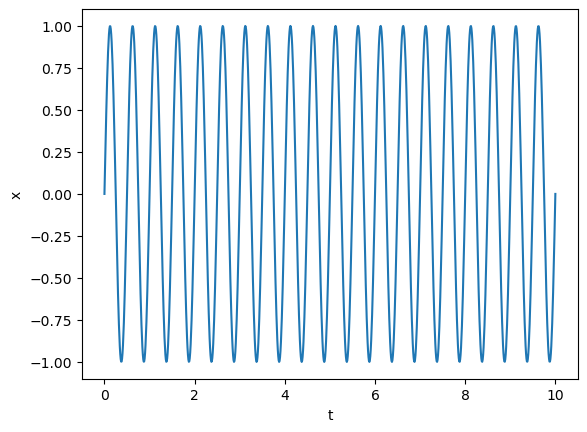

In [23]:
plt.plot(t,x)
plt.xlabel("t")
plt.ylabel("x")

In [24]:
x_ft = np.fft.fft(x)
np.fft.fftfreq?

Signature: np.fft.fftfreq(n, d=1.0)
Docstring:
Return the Discrete Fourier Transform sample frequencies.

The returned float array `f` contains the frequency bin centers in cycles
per unit of the sample spacing (with zero at the start).  For instance, if
the sample spacing is in seconds, then the frequency unit is cycles/second.

Given a window length `n` and a sample spacing `d`::

  f = [0, 1, ...,   n/2-1,     -n/2, ..., -1] / (d*n)   if n is even
  f = [0, 1, ..., (n-1)/2, -(n-1)/2, ..., -1] / (d*n)   if n is odd

Parameters
----------
n : int
    Window length.
d : scalar, optional
    Sample spacing (inverse of the sampling rate). Defaults to 1.

Returns
-------
f : ndarray
    Array of length `n` containing the sample frequencies.

Examples
--------
>>> signal = np.array([-2, 8, 6, 4, 1, 0, 3, 5], dtype=float)
>>> fourier = np.fft.fft(signal)
>>> n = signal.size
>>> timestep = 0.1
>>> freq = np.fft.fftfreq(n, d=timestep)
>>> freq
array([ 0.  ,  1.25,  2.5 , ..., -3.75, -2.5 , -1

### Plotting

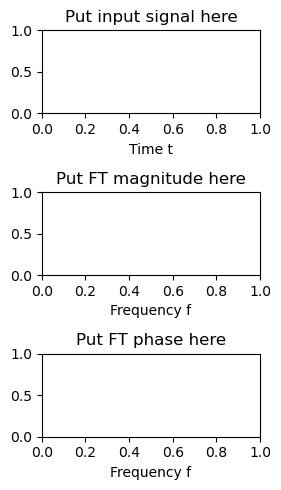

In [25]:
fig, ax = plt.subplots(3, 1, figsize=(3, 5))

ax[0].set_title("Put input signal here")
ax[0].set_xlabel("Time t")
#....
ax[1].set_title("Put FT magnitude here")
ax[1].set_xlabel("Frequency f")
#....
ax[2].set_title("Put FT phase here")
ax[2].set_xlabel("Frequency f")
#...

fig.tight_layout()

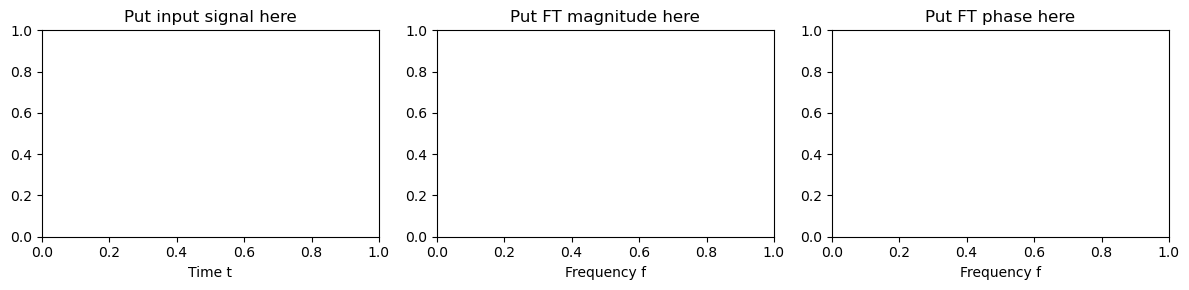

In [26]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3))

ax[0].set_title("Put input signal here")
ax[0].set_xlabel("Time t")
#....
ax[1].set_title("Put FT magnitude here")
ax[1].set_xlabel("Frequency f")
#....
ax[2].set_title("Put FT phase here")
ax[2].set_xlabel("Frequency f")
#...

fig.tight_layout()

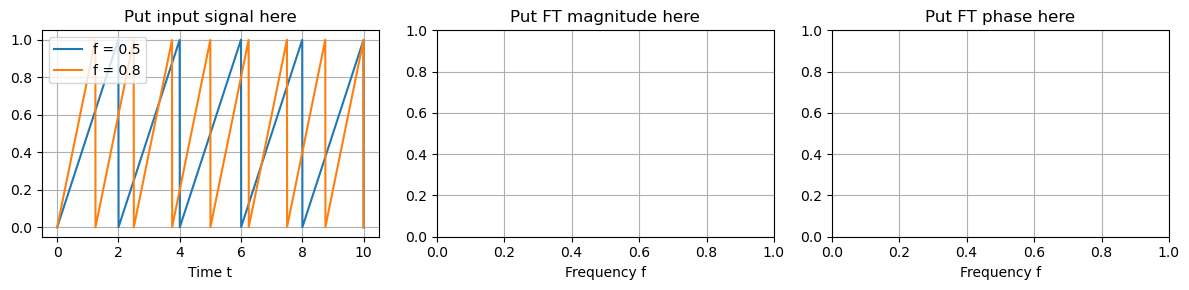

In [27]:
fig, axs = plt.subplots(1, 3, figsize=(12, 3))
ax_t, ax_f, ax_p = axs

t = np.linspace(0, 10, 2048)
f = 0.5 # Frequency
T = 1/(f) # Period
f2 = 0.8 # Frequency
T2 = 1/(f2) # Period


ax_t.set_title("Put input signal here")
ax_t.set_xlabel("Time t")
ax_t.plot(t, (t%T)/T, label="f = 0.5")
ax_t.plot(t, (t%T2)/T2, label="f = 0.8")
ax_t.legend()
#....
ax_f.set_title("Put FT magnitude here")
ax_f.set_xlabel("Frequency f")
#....
ax_p.set_title("Put FT phase here")
ax_p.set_xlabel("Frequency f")
#...


for ax in axs:
    ax.grid(True)
fig.tight_layout()

## 1-D convolution

In [28]:
a = [1,1,1,0,0,0,0,1,1,1,0,0,0,1,0,0,0,1,1,1,0,1,1,0,0,0,0]
v = [1,1,1]



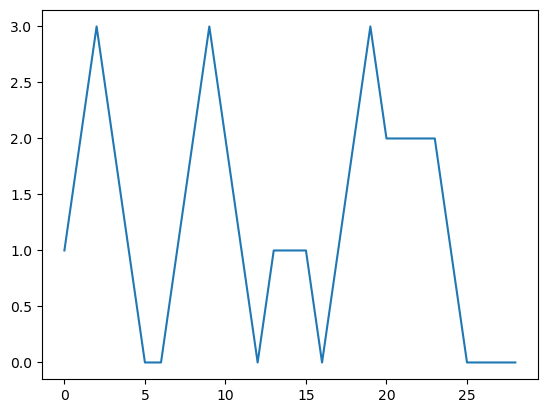

In [29]:
plt.plot(np.arange(len(np.convolve(a,v, mode='full'))), np.convolve(a,v, mode='full'))

### Convolution attempt (bringing circuits analogy) 

In [30]:
import numpy as np
from scipy import signal
import matplotlib.pyplot as plt
N = 500
t = np.linspace(0, 1, N, endpoint=False)
t_input = np.linspace(0, 5, N*5, endpoint=False)
signal_freq = 5
# dt = t[1] - t[0]
# nonsinu_signal = signal.square(2 * np.pi * signal_freq * t)

In [31]:
tau = 0.1
h_t = np.exp(-t/tau)
input_signal = signal.square(2 * np.pi * signal_freq * t_input) #cont_signal(t, freq)

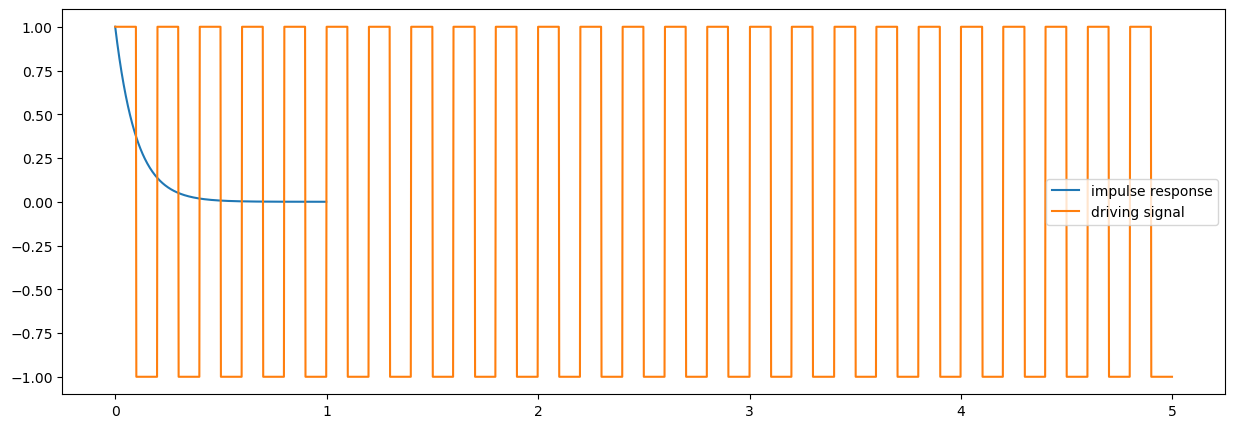

In [32]:
fig, ax = plt.subplots(figsize = (15,5))
ax.plot(t, h_t, label = "impulse response")
ax.plot(t_input, input_signal, label= "driving signal")
ax.legend()

In [33]:
response = np.convolve(input_signal, h_t, mode = "same")

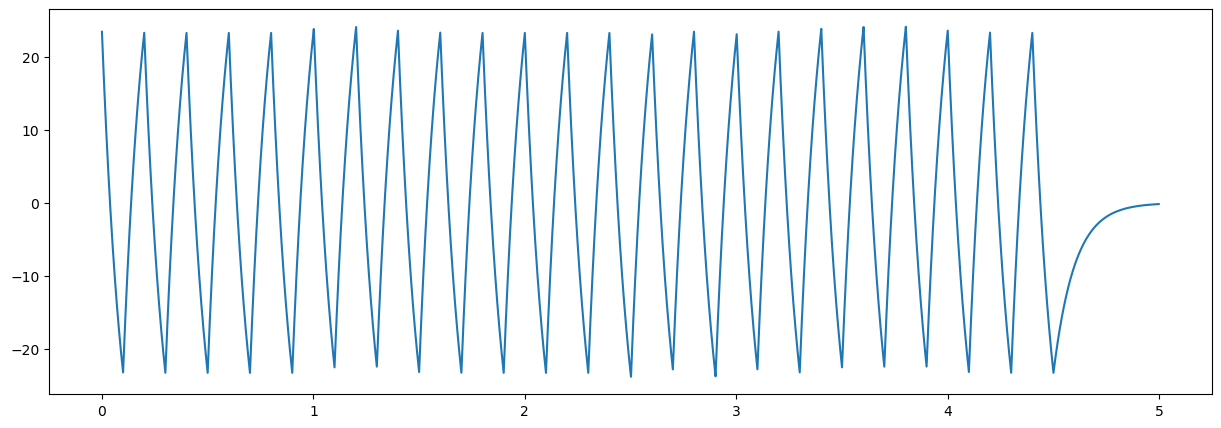

In [34]:
fig, ax = plt.subplots(figsize = (15,5))
#ax.plot(t, input_signal)
ax.plot(t_input, response)

In [35]:
fourier_length = len(h_t) + len(input_signal) - 1

In [36]:
fourier_input = np.fft.fft(input_signal, n = fourier_length)
fourier_h = np.fft.fft(h_t, n = fourier_length)

In [37]:
fourier_response = fourier_h*fourier_input 

In [38]:
response = np.real(np.fft.ifft(fourier_response))

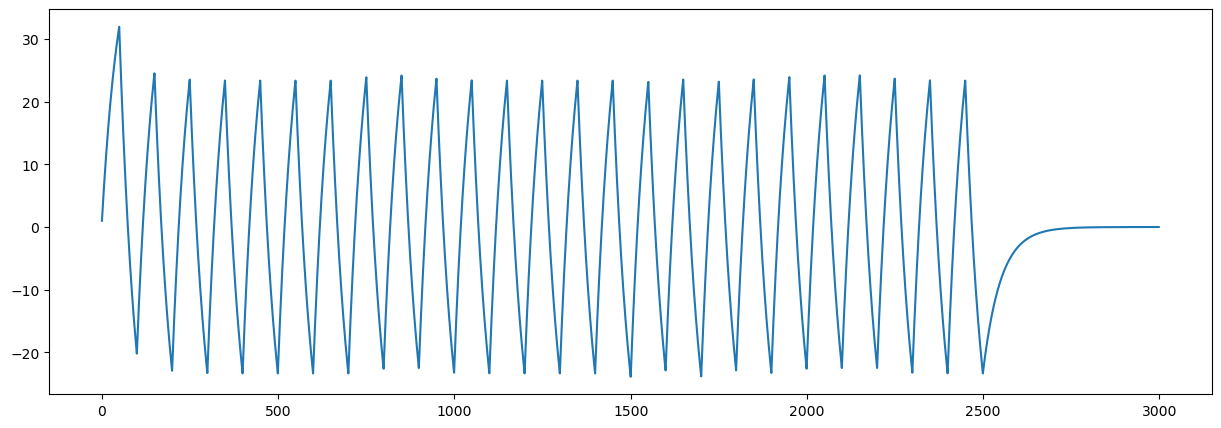

In [39]:
fig, ax = plt.subplots(figsize = (15,5))

ax.plot(response)